# 实验 02：第一个 PINN 与最大误差界

目标：把已学习的一维 Poisson 方程、硬边界 PINN、残差和误差界接起来。

问题：$-u''=2$，$x\in(0,1)$，$u(0)=u(1)=0$。精确解 $u^*(x)=x(1-x)$ 只用于事后检查，不参与训练和误差界构造。

这只是代码和理论连接的入门算例。该精确解对应内部网络常数 $N_\theta=1$，因此它本身不能证明方法在更复杂问题上的优势。

需要 Python、PyTorch、NumPy、Matplotlib。若缺少包，可在自己的 notebook 环境运行 `%pip install torch numpy matplotlib`。本实验使用 CPU、双精度和固定随机种子，不需要 GPU；不同版本可能产生略有不同的训练结果。


In [1]:
import platform
import time
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.manual_seed(7)
np.random.seed(7)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Device: CPU; dtype: float64; seed: 7")


Python: 3.12.14
PyTorch: 2.14.1+cpu
Device: CPU; dtype: float64; seed: 7


## 1. 网络：输入位置，输出近似解

内部网络为 $N_\theta(x)=c+\sum_{j=1}^{16}a_j\tanh(w_jx+b_j)$。

最终近似解 $v_\theta(x)=x(1-x)N_\theta(x)$。因子 $x(1-x)$ 保证两端为零，所以本例不需要边界罚项。


In [2]:
class PoissonPINN(nn.Module):
    def __init__(self, width=16):
        super().__init__()
        self.hidden = nn.Linear(1, width)
        self.output = nn.Linear(width, 1)

    def forward(self, x):
        n = self.output(torch.tanh(self.hidden(x)))
        return x * (1.0 - x) * n

model = PoissonPINN()
endpoints = torch.tensor([[0.0], [1.0]])
print("Number of parameters:", sum(p.numel() for p in model.parameters()))
print("Boundary outputs:", model(endpoints).detach().flatten().tolist())
assert torch.equal(model(endpoints).detach(), torch.zeros_like(endpoints))


Number of parameters: 49
Boundary outputs: [-0.0, -0.0]


## 2. 自动微分与残差

`requires_grad_(True)` 告诉 PyTorch 需要跟踪对位置 $x$ 的导数。

`create_graph=True` 保留导数运算的计算图，使我们能继续计算二阶导数，并把残差损失对网络参数反向传播。

网络对批次中的每个样本独立计算，所以以下 `autograd.grad` 写法可以得到逐点的空间导数。

官方说明：https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad.html


In [3]:
def dx(y, x):
    return torch.autograd.grad(
        y, x, grad_outputs=torch.ones_like(y), create_graph=True
    )[0]

def residual(model, x):
    v = model(x)
    v_x = dx(v, x)
    v_xx = dx(v_x, x)
    return -v_xx - 2.0

# 用解析解检查求导与残差的符号；这不是训练数据。
check_x = torch.linspace(0, 1, 17).reshape(-1, 1).requires_grad_(True)
check_u = check_x * (1-check_x)
check_r = -dx(dx(check_u, check_x), check_x) - 2.0
print("Residual of the analytic solution:", check_r.detach().abs().max().item())
assert check_r.detach().abs().max().item() == 0.0


Residual of the analytic solution: 0.0


## 3. 独立评估与理论界的数值实现

训练用 128 个内部配点。评估残差使用包含两端的 1001 点等距网格，$h=0.001$；参考解误差使用 10001 点网格估计。

密集网格误差记为 **reference-grid maximum error**，不能称为已经严格求得的连续最大误差。

对当前单隐藏层网络，利用 $|\tanh'|\leq1$、$|\tanh''|\leq2$、$|\tanh^{(3)}|\leq2$，定义：

$$B_1=\sum|a_jw_j|,\quad B_2=2\sum|a_j||w_j|^2,\quad B_3=2\sum|a_j||w_j|^3.$$

由乘积求导，$|v^{(3)}|\leq M=B_3/4+3B_2+6B_1$。因此在精确算术下：

$$\|v-u^*\|_\infty\leq\eta=\frac18\left(R_{\rm grid}+\frac{Mh}{2}\right).$$

**保证的边界：** 这里对理论上有效的公式进行普通 float64 数值评估，尚未对残差求值和权重求和实施舍入误差包络，不能宣称得到机器级严格证书。评估网格上的数值检查支持实现正确性，但不代替连续理论证明。


In [4]:
def derivative_bound(model):
    w = model.hidden.weight.detach().reshape(-1)
    a = model.output.weight.detach().reshape(-1)
    b1 = torch.sum(torch.abs(a*w)).item()
    b2 = (2*torch.sum(torch.abs(a)*w.abs()**2)).item()
    b3 = (2*torch.sum(torch.abs(a)*w.abs()**3)).item()
    return 0.25*b3 + 3*b2 + 6*b1

def evaluate(model, step):
    xr = torch.linspace(0, 1, 1001).reshape(-1, 1).requires_grad_(True)
    rr = residual(model, xr)
    r_grid = rr.detach().abs().max().item()
    xe = torch.linspace(0, 1, 10001).reshape(-1, 1)
    with torch.no_grad():
        e_grid = (model(xe) - xe*(1-xe)).abs().max().item()
        bc = model(endpoints).abs().max().item()
    m = derivative_bound(model)
    h = 1.0 / 1000
    eta_residual = r_grid/8
    eta_gap = m*h/16
    eta = eta_residual + eta_gap
    # 代码检查：比较采样导数与解析构造的全域界。
    v = model(xr)
    v3 = dx(dx(dx(v, xr), xr), xr)
    assert v3.detach().abs().max().item() <= m + 1e-10
    assert e_grid <= eta + 1e-10
    assert bc == 0.0
    return dict(step=step, r_grid=r_grid, error_grid=e_grid, M=m,
                eta_residual=eta_residual, eta_gap=eta_gap, eta=eta,
                ratio_grid=eta/e_grid if e_grid else float("inf"))


## 4. 训练：只有方程残差，没有精确解标签

每一步最小化 $L=\frac1{128}\sum_i(-v_\theta''(x_i)-2)^2$。

`loss.backward()` 对网络参数计算梯度；这里应区分“对坐标求导以构造 PDE 残差”与“对参数求导以更新网络”。

记录初始化、100、500、2000 步的结果，观察不同训练程度下界的行为。这是单个随机种子的入门实验，不是完整的性能评测。


In [5]:
x_train_base = torch.linspace(0, 1, 130)[1:-1].reshape(-1, 1)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_history = []
records = [evaluate(model, 0)]
start = time.perf_counter()

for step in range(1, 2001):
    x_train = x_train_base.detach().clone().requires_grad_(True)
    optimizer.zero_grad(set_to_none=True)
    r = residual(model, x_train)
    loss = (r**2).mean()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if step in (100, 500, 2000):
        records.append(evaluate(model, step))

elapsed = time.perf_counter() - start
print(f"Training plus checkpoint evaluation: {elapsed:.2f} seconds")
print("step    reference-grid error    grid max residual     bound eta         M")
for row in records:
    print(f'{row["step"]:4d}    {row["error_grid"]:20.6e} '
          f'{row["r_grid"]:20.6e} {row["eta"]:14.6e} {row["M"]:10.4f}')
last = records[-1]
print("Final bound decomposition:")
print(f'  residual term R_grid/8: {last["eta_residual"]:.6e}')
print(f'  gap term M*h/16:        {last["eta_gap"]:.6e}')
print(f'  bound / grid error:    {last["ratio_grid"]:.3f}')
assert last["error_grid"] < records[0]["error_grid"]


Training plus checkpoint evaluation: 2.39 seconds
step    reference-grid error    grid max residual     bound eta         M
   0            3.246122e-01         2.826054e+00   3.540000e-01    11.8911
 100            3.907852e-03         1.752226e-01   2.243762e-02     8.5567
 500            2.840965e-04         3.545665e-02   4.913921e-03     7.7094
2000            2.697409e-05         7.358162e-03   1.415910e-03     7.9382
Final bound decomposition:
  residual term R_grid/8: 9.197703e-04
  gap term M*h/16:        4.961394e-04
  bound / grid error:    52.491


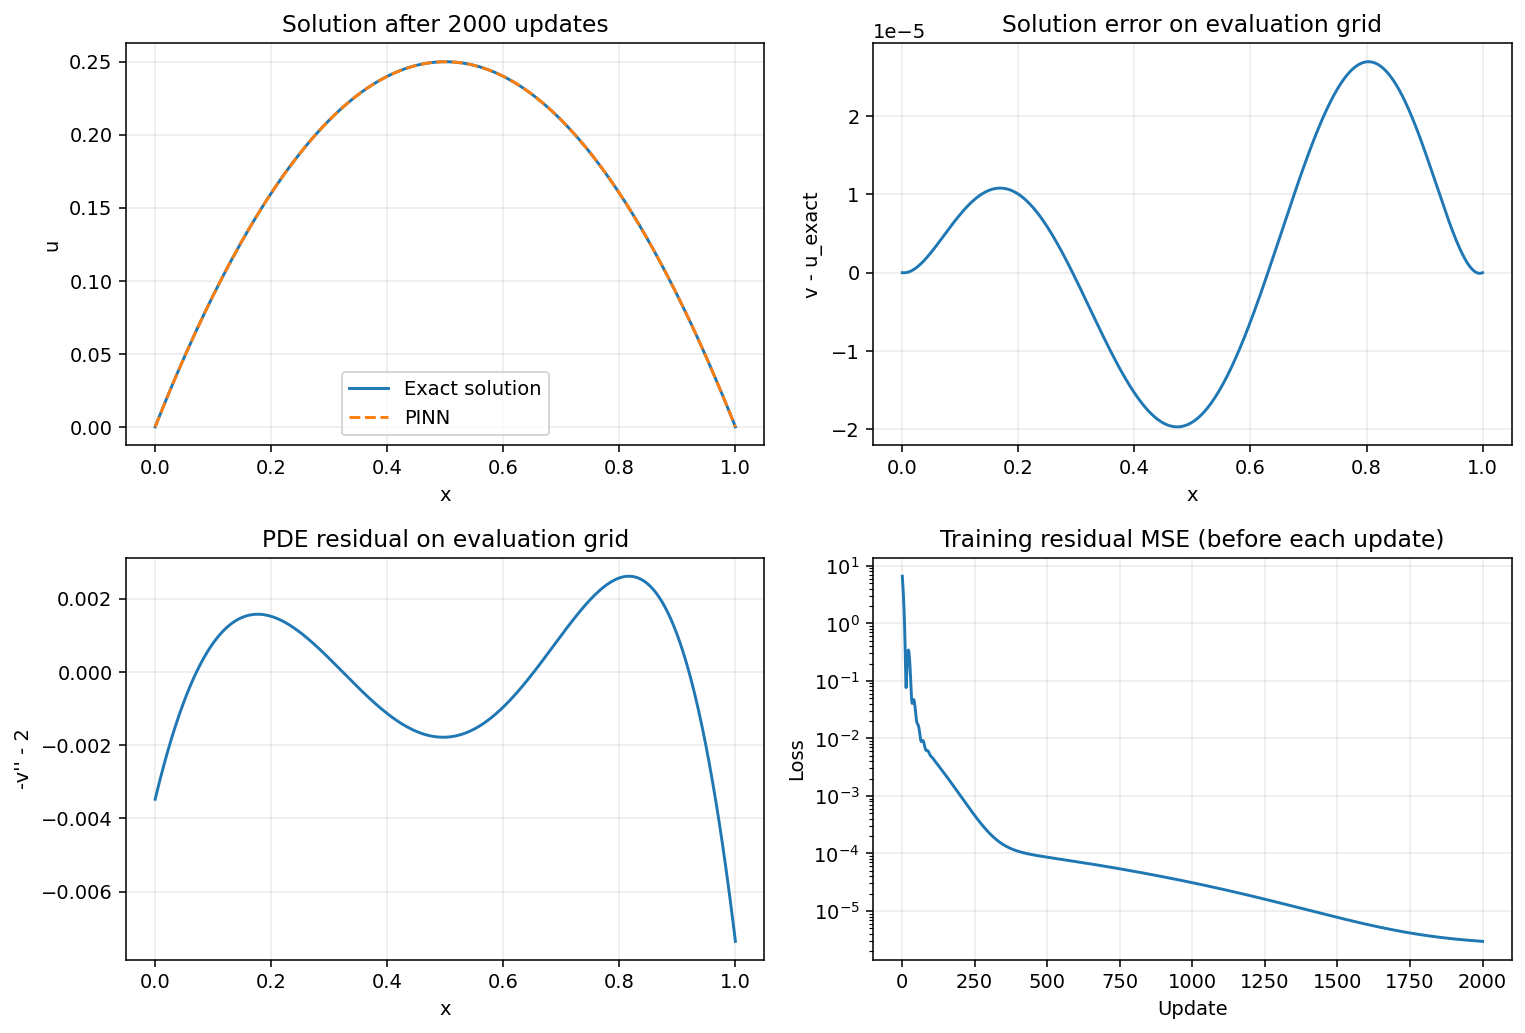

In [6]:
xp = torch.linspace(0, 1, 1001).reshape(-1, 1).requires_grad_(True)
vp = model(xp)
rp = residual(model, xp)
xx = xp.detach().numpy().flatten()
vv = vp.detach().numpy().flatten()
uu = xx*(1-xx)
rr = rp.detach().numpy().flatten()

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
axes[0, 0].plot(xx, uu, label="Exact solution")
axes[0, 0].plot(xx, vv, "--", label="PINN")
axes[0, 0].set(title="Solution after 2000 updates", xlabel="x", ylabel="u")
axes[0, 0].legend()
axes[0, 1].plot(xx, vv-uu)
axes[0, 1].set(title="Solution error on evaluation grid", xlabel="x", ylabel="v - u_exact")
axes[1, 0].plot(xx, rr)
axes[1, 0].set(title="PDE residual on evaluation grid", xlabel="x", ylabel="-v'' - 2")
axes[1, 1].semilogy(np.arange(1, 2001), loss_history)
axes[1, 1].set(title="Training residual MSE (before each update)", xlabel="Update", ylabel="Loss")
for ax in axes.flat:
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## 5. 读懂结果，而不仅看训练损失

请比较最后输出的两个项：$R_{\rm grid}/8$ 与 $Mh/16$。前者来自残差，后者来自采样点间的覆盖修正。如果后者很大，继续降低训练损失未必能明显改善最终上界。

下面在同一个训练结果上改变评估网格。该操作不重新训练网络。它展示采样覆盖成本的影响，不是网络精度的变化。


In [7]:
print("intervals   grid residual term    gap correction       total bound")
for intervals in (100, 1000, 10000):
    xg = torch.linspace(0, 1, intervals+1).reshape(-1, 1).requires_grad_(True)
    rg = residual(model, xg).detach().abs().max().item()
    term_r = rg/8
    term_gap = last["M"]/(16*intervals)
    print(f"{intervals:9d} {term_r:20.6e} {term_gap:18.6e} {term_r+term_gap:18.6e}")


intervals   grid residual term    gap correction       total bound
      100         9.197703e-04       4.961394e-03       5.881164e-03
     1000         9.197703e-04       4.961394e-04       1.415910e-03
    10000         9.197703e-04       4.961394e-05       9.693842e-04


## 后续实验方向

- 当前问题是易于手算的检查算例；下一组可换成 $f(x)=\pi^2\sin(\pi x)$，精确解为 $\sin(\pi x)$。此时 $M$ 还要包含 $\|f'\|_\infty=\pi^3$，不能照搬常数源项的公式。
- 在相同误差目标下，比较全域权重导数界与分区局部界的成本、紧致程度。
- 增加随机种子、训练程度和评估网格实验，再形成中期报告中的系统结果。
- 如果报告使用“严格数值认证”这一表述，应继续实现舍入误差包络或经过验证的区间计算。

本笔记实现经典误差界的基线，不声称新的理论贡献。
